In [163]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [164]:
from sklearn.model_selection import train_test_split

In [165]:
m_df = pd.read_csv(r'C:\Users\acces\OneDrive\Desktop\ML PROJECT\master_late_delivery.csv')

In [166]:
m_df.head()

,order_id,customer_id,order_purchase_timestamp,order_estimated_delivery_date,is_late,customer_city,customer_state,total_items,total_price,total_freight_value,...,avg_length,avg_width,total_payments,total_value,max_installments,total_sellers,seller_state_count,same_state_seller_count,seller_state,multiple_seller_state
0,00024acbcdf0a6daa1e931b038114c75,d4eb9395c8c0431ee92fce09860c5a06,2018-08-08 10:00:35.0000000,2018-08-20 00:00:00.0000000,0,atibaia,SP,1,12.99,12.79,...,16.0,15.0,1.0,25.78,2.0,1,1,1,SP,0
1,00048cc3ae777c65dbb7d2a0634bc1ea,816cbea969fe5b689b39cfc97a506742,2017-05-15 21:42:34.0000000,2017-06-06 00:00:00.0000000,0,uberaba,MG,1,21.90,12.69,...,24.0,15.0,1.0,34.59,1.0,1,1,0,SP,0
2,000e906b789b55f64edcb1f84030f90d,6a3b2fc9f270df258605e22bef19fd88,2017-11-21 18:54:23.0000000,2017-12-07 00:00:00.0000000,1,santa cruz do rio pardo,SP,1,21.99,11.85,...,17.0,12.0,1.0,33.84,3.0,1,1,1,SP,0
3,00130c0eee84a3d909e75bc08c5c3ca1,47d656c08a282ec5ab4c1f18303a3a30,2018-06-11 21:17:00.0000000,2018-06-20 00:00:00.0000000,0,sao bernardo do campo,SP,1,27.90,7.94,...,17.0,13.0,1.0,35.84,1.0,1,1,1,SP,0
4,0020a222f55eb79a372d0efee3cca688,0c45155afd8ff99622c40824057f9b34,2017-08-15 02:45:18.0000000,2017-09-06 00:00:00.0000000,0,volta redonda,RJ,1,29.99,15.10,...,26.0,22.0,1.0,45.09,4.0,1,1,0,SP,0


In [167]:
m_df.shape

(96470, 32)

In [168]:
m_df.columns.tolist()

['order_id',
 'customer_id',
 'order_purchase_timestamp',
 'order_estimated_delivery_date',
 'is_late',
 'customer_city',
 'customer_state',
 'total_items',
 'total_price',
 'total_freight_value',
 'avg_price',
 'product_rows',
 'total_weight',
 'total_height',
 'total_length',
 'total_width',
 'max_heigth',
 'max_weight',
 'max_length',
 'max_width',
 'avg_weight',
 'avg_heigth',
 'avg_length',
 'avg_width',
 'total_payments',
 'total_value',
 'max_installments',
 'total_sellers',
 'seller_state_count',
 'same_state_seller_count',
 'seller_state',
 'multiple_seller_state']

In [169]:
model_df = pd.read_csv(r'C:\Users\acces\OneDrive\Desktop\ML PROJECT\model_data.csv')

In [170]:
model_df.head()

,purchase_month,purchase_day,purchase_weekday,purchase_hour,estimated_delivery_days,total_weight,total_volume,product_rows,max_weight,total_price,...,freight_per_kg,freight_price_ratio,customer_state,seller_state,same_state,order_size,weight_category,missing_weights,weight_zero,is_late
0,8,8,2,10,11.582928,200.0,2400.0,1,200.0,12.99,...,0.000064,0.984604,SP,SP,1,small,light,0,0,0
1,5,15,0,21,21.095440,450.0,2880.0,1,450.0,21.90,...,0.000028,0.579452,MG,SP,0,small,light,0,0,0
2,11,21,1,18,15.212234,300.0,816.0,1,300.0,21.99,...,0.000039,0.538881,SP,SP,1,small,light,0,0,1
3,6,11,0,21,8.113194,150.0,2873.0,1,150.0,27.90,...,0.000053,0.284588,SP,SP,1,small,light,0,0,0
4,8,15,1,2,21.885208,700.0,4576.0,1,700.0,29.99,...,0.000022,0.503501,RJ,SP,0,small,light,0,0,0


#### CREATING SEPARATE FEATURES AND TARGET VARIABLE

In [171]:
X = model_df.drop(columns=['is_late'])

In [172]:
Y = model_df['is_late']

In [173]:
print(X.shape)
print(Y.shape)

(96470, 20)
(96470,)


In [174]:
Y.value_counts()

is_late
0    88644
1     7826
Name: count, dtype: int64

In [175]:
Y.value_counts(normalize=True)*100

is_late
0    91.887633
1     8.112367
Name: proportion, dtype: float64

#### TRAINING AND EVALUATION

In [176]:
X_train, x_test, Y_train, y_test = train_test_split( X,Y, test_size=0.2,random_state=42, stratify=Y)

In [177]:
print("X_train:", X_train.shape)
print("Y_train:", Y_train.shape)
print("x_test:", x_test.shape)
print("y_test:", y_test.shape)


X_train: (77176, 20)
Y_train: (77176,)
x_test: (19294, 20)
y_test: (19294,)


In [178]:
print(Y_train.value_counts(normalize=True)*100)
print(y_test.value_counts(normalize=True)*100)

is_late
0    91.887374
1     8.112626
Name: proportion, dtype: float64
is_late
0    91.88867
1     8.11133
Name: proportion, dtype: float64


#### SPLITING NUMERICAL AND CATEGORICAL COLUMNS FOR PREPROCESSING

In [179]:
num_cols = X_train.select_dtypes(include=['int64','float64']).columns.tolist()
print(f"numerical_columns:{num_cols}")
for col in num_cols:
    print(col)
cat_cols = X_train.select_dtypes(include=['str','category']).columns.tolist()
print(f"category_columns:{cat_cols}")

numerical_columns:['purchase_month', 'purchase_day', 'purchase_weekday', 'purchase_hour', 'estimated_delivery_days', 'total_weight', 'total_volume', 'product_rows', 'max_weight', 'total_price', 'total_freight_value', 'freight_per_kg', 'freight_price_ratio', 'same_state', 'missing_weights', 'weight_zero']
purchase_month
purchase_day
purchase_weekday
purchase_hour
estimated_delivery_days
total_weight
total_volume
product_rows
max_weight
total_price
total_freight_value
freight_per_kg
freight_price_ratio
same_state
missing_weights
weight_zero
category_columns:['customer_state', 'seller_state', 'order_size', 'weight_category']


#### IMPORT PREPROCESSING TOOLS

In [180]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

#### NUMERICAL AND CATEGORICAL PREPROCESSING PIPELINES

In [181]:
num_pipeline = Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),('scaler', StandardScaler())])

In [182]:
cat_pipeline = Pipeline(steps=[('imputer', 3SimpleImputer(strategy='most_frequent')), ('encoder', OneHotEncoder(handle_unknown='ignore'))])

SyntaxError: invalid decimal literal (1842425446.py, line 1)

In [ ]:
preprocessing = ColumnTransformer(transformers=[
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

#### FIT AND TRANSFORM THE DATA

In [ ]:
X_train_processed = preprocessing.fit_transform(X_train)
X_test_processed = preprocessing.transform(x_test)

In [ ]:
print(f"X_training_shape: {X_train_processed.shape}")
print(f"x_test_shape: {X_test_processed.shape}")

X_training_shape: (77176, 72)
x_test_shape: (19294, 72)


## MODEL TRAINING

#### LOGISTIC REGRESSION

In [ ]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(                        
    class_weight = 'balanced',                     
    max_iter=1000,                                 
    random_state=42                                
)                                                  
model.fit(X_train_processed, Y_train)              

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to u

In [ ]:
y_pred = model.predict(X_test_processed)

In [ ]:
from sklearn.metrics import classification_report

In [ ]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.96      0.65      0.77     17729
           1       0.14      0.67      0.24      1565

    accuracy                           0.65     19294
   macro avg       0.55      0.66      0.50     19294
weighted avg       0.89      0.65      0.73     19294



In [ ]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y_test, y_pred)
print(cm)

[[11503  6226]
 [  524  1041]]


#### RANDOMFORESTCLASSIFIER

In [ ]:
from sklearn.ensemble import RandomForestClassifier

In [ ]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

In [ ]:
rf_model.fit(X_train_processed, Y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_fe

In [ ]:
y_pred_rf = rf_model.predict(X_test_processed)

In [ ]:
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.93      0.98      0.95     17729
           1       0.43      0.17      0.25      1565

    accuracy                           0.91     19294
   macro avg       0.68      0.58      0.60     19294
weighted avg       0.89      0.91      0.90     19294



In [ ]:
cmf = confusion_matrix(y_test, y_pred_rf)
print(cmf)

[[17375   354]
 [ 1297   268]]


#### XGBOOST

In [ ]:
from xgboost import XGBClassifier

In [ ]:
xgb_model = XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=5,
    scale_pos_weight=10,
    random_state=42,
    eval_metric='logloss',
    n_jobs=-1
)


In [ ]:
xgb_model.fit(X_train_processed, Y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [ ]:
y_pred_xgb = xgb_model.predict(X_test_processed)

In [ ]:
print(classification_report(y_test, y_pred_xgb))

              precision    recall  f1-score   support

           0       0.96      0.79      0.87     17729
           1       0.21      0.62      0.31      1565

    accuracy                           0.78     19294
   macro avg       0.58      0.71      0.59     19294
weighted avg       0.90      0.78      0.82     19294



In [ ]:
cm_xgb = confusion_matrix(y_test, y_pred_xgb)
print(cm_xgb)

[[14073  3656]
 [  598   967]]


##### EXTRACTING THE PROBABILITIES

In [ ]:
y_prob_xgb = xgb_model.predict_proba(X_test_processed)[:, 1]

In [ ]:
y_prob_50 = (y_prob_xgb >= 0.50).astype(int)
y_prob_40 = (y_prob_xgb >= 0.40).astype(int)
y_prob_35 = (y_prob_xgb >= 0.35).astype(int)
y_prob_30 = (y_prob_xgb >= 0.30).astype(int)


In [ ]:
from sklearn.metrics import precision_score, f1_score, recall_score

thresholds = {
    0.50: y_prob_50,
    0.40: y_prob_40,
    0.35: y_prob_35,
    0.30: y_prob_30
}
for threshold, prediction in thresholds.items():
    print(f"threshold: {threshold}")
    print(f"precision: {precision_score(y_test, prediction)}")
    print(f"recall: {recall_score(y_test, prediction)}")
    print(f"f1 score: {f1_score(y_test, prediction)}")

threshold: 0.5
precision: 0.209171533636167
recall: 0.6178913738019169
f1 score: 0.3125404007756949
threshold: 0.4
precision: 0.16997953814674072
recall: 0.7431309904153355
f1 score: 0.2766742000713691
threshold: 0.35
precision: 0.14713800772562333
recall: 0.8031948881789137
f1 score: 0.2487138899881282
threshold: 0.3
precision: 0.12888344944454905
recall: 0.8747603833865815
f1 score: 0.224665627307787


##### OBSERVATION
XGBOOST has highest f1 score while the LOGISTIC REGRESSION model has highest recall but lower precision and RANDOM FOREST CLASSIFIER  has hiughest precision but lower recall. We will go forward with XGBOOST considering its higher f1 score

#### SPLITING THE TRAINING SET FOR VALIDATION

In [ ]:
X_train_sub, X_val, Y_train_sub, Y_val = train_test_split(
    X_train,
    Y_train,
    test_size=0.2,
    random_state=42,
    stratify=Y_train
)

In [ ]:
print(X_train_sub.shape)
print(X_val.shape)

(61740, 20)
(15436, 20)


##### PREPROCESSING TRAINING AND VALIDATION DATA

In [ ]:
X_train_preprocessed = preprocessing.fit_transform(X_train_sub)
X_val_processed = preprocessing.transform(X_val)

In [ ]:
model = LogisticRegression(
    class_weight='balanced',
    max_iter=1000,
    random_state=42
)

model.fit(X_train_preprocessed,Y_train_sub)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to u

In [ ]:
Y_val_proba = model.predict_proba(X_val_processed)[:,1]

In [ ]:
threshold = [0.05, 0.30, 0.35, 0.40, 0.50]
for threshold in thresholds:
    y_pred = (Y_val_proba >= threshold).astype(int)
    print(f"threshold: {threshold}")                          
    print(f"precision: {precision_score(Y_val, y_pred)}")
    print(f"recall: {recall_score(Y_val,y_pred)}")      
    print(f"f1 score: {f1_score(Y_val, y_pred)}")        

threshold: 0.5
precision: 0.13676671214188268
recall: 0.6405750798722045
f1 score: 0.22540753232152894
threshold: 0.4
precision: 0.11206526406182911
recall: 0.8338658146964856
f1 score: 0.1975775927327782
threshold: 0.35
precision: 0.10226343059721843
recall: 0.8985623003194888
f1 score: 0.183628499143067
threshold: 0.3
precision: 0.09436235142948923
recall: 0.9384984025559105
f1 score: 0.1714827787507297


##### OBSERVATION
The F1 score of threshold 0.50 is better than all other thresholds

In [ ]:
from sklearn.ensemble import RandomForestClassifier
rf_model = RandomForestClassifier(
    n_estimators= 200,
    class_weight='balanced',
    max_depth=15,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)


In [ ]:
rf_model.fit(X_train_preprocessed, Y_train_sub)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",15
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_fea

In [ ]:
rf_val_proba = rf_model.predict_proba(X_val_processed)[:,1]

In [ ]:
threshold = [0.05, 0.30, 0.35, 0.40, 0.50]                    
for threshold in thresholds:                                  
    y_pred = (rf_val_proba >= threshold).astype(int)           
    print(f"threshold: {threshold}")                          
    print(f"precision: {precision_score(Y_val, y_pred)}")     
    print(f"recall: {recall_score(Y_val,y_pred)}")            
    print(f"f1 score: {f1_score(Y_val, y_pred)}")             

threshold: 0.5
precision: 0.23480947476828012
recall: 0.5463258785942492
f1 score: 0.3284513805522209
threshold: 0.4
precision: 0.15541422048271364
recall: 0.7611821086261981
f1 score: 0.25812567713976164
threshold: 0.35
precision: 0.12787236575782832
recall: 0.8578274760383386
f1 score: 0.2225676095741374
threshold: 0.3
precision: 0.10428022518094898
recall: 0.9321086261980831
f1 score: 0.187575343566664


##### OBSERVATIONS
F1 score of threshold 0.50 is better than all other thresholds at 0.32, while with reduction inthreshold levels the recall goes up but the precision suffers.

##### FEATURES THAT INFLUENCE THE MOST IN RFC OUTPUTS

In [ ]:
import pandas as pd
feature_importance = pd.Series(rf_model.feature_importances_,
index = preprocessing.get_feature_names_out()).sort_values(ascending=False)
print(feature_importance.head(15))

num__purchase_month             0.180432
num__estimated_delivery_days    0.175169
num__total_freight_value        0.066228
num__freight_per_kg             0.049566
num__purchase_day               0.048927
num__freight_price_ratio        0.046727
num__total_price                0.046270
num__total_volume               0.045718
num__max_weight                 0.041637
num__total_weight               0.039675
cat__customer_state_SP          0.033970
num__purchase_hour              0.031110
cat__customer_state_RJ          0.023313
num__purchase_weekday           0.022929
num__same_state                 0.019149
dtype: float64


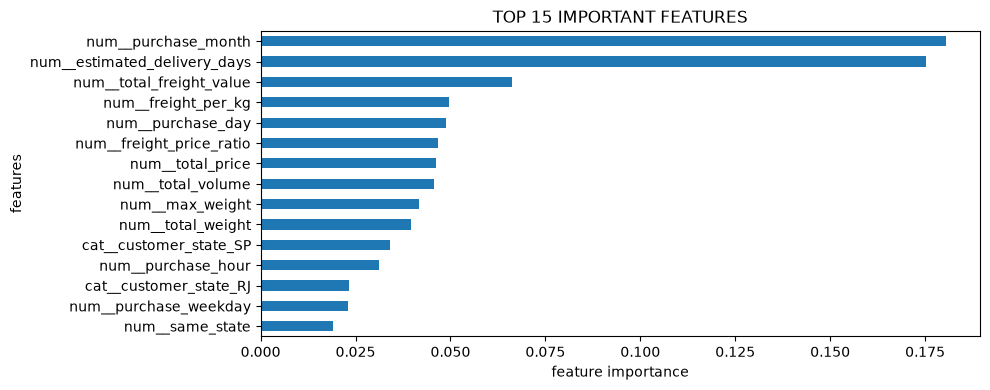

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
feature_importance.head(15).sort_values().plot(kind='barh',figsize=(10,4))
plt.title('TOP 15 IMPORTANT FEATURES')
plt.xlabel('feature importance')
plt.ylabel('features')
plt.tight_layout()
plt.show()


In [ ]:
from xgboost import XGBClassifier

In [ ]:
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=11,
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)


In [ ]:
xgb_model.fit(X_train_preprocessed, Y_train_sub)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,0.8
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [ ]:
xgb_val_proba = xgb_model.predict_proba(X_val_processed)[:,1]

In [ ]:
threshold = [0.05, 0.30, 0.35, 0.40, 0.50]                    
for threshold in thresholds:                                  
    y_pred = (xgb_val_proba >= threshold).astype(int)          
    print(f"threshold: {threshold}")                          
    print(f"precision: {precision_score(Y_val, y_pred)}")     
    print(f"recall: {recall_score(Y_val,y_pred)}")            
    print(f"f1 score: {f1_score(Y_val, y_pred)}")             

threshold: 0.5
precision: 0.21157371039539147
recall: 0.645367412140575
f1 score: 0.3186748175902189
threshold: 0.4
precision: 0.1690463599506434
recall: 0.7659744408945687
f1 score: 0.27696750902527073
threshold: 0.35
precision: 0.14811104751001716
recall: 0.8266773162939297
f1 score: 0.2512135922330097
threshold: 0.3
precision: 0.1280232558139535
recall: 0.8793929712460063
f1 score: 0.22350791717417784


##### OBSERVATION
XGBOOST F1 score is better at threshold 0.50, also precision and recall is much better at this level.


##### XGBOOST hyperparameters tuning

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

In [ ]:
param_grid = {
    'n_estimators': [200,300,500],
    'max_depth': [3,5,7],
    'learning_rate': [0.01,0.05,0.1],
    'subsample': [0.8,1.0],
    'colsample_bytree': [0.8,1.0],
    'min_child_weight': [1,5,10]
}

In [ ]:
random_search = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=param_grid,
    n_iter=20,
    scoring='f1',
    cv=3,
    verbose=1,
    random_state=42,
    n_jobs=-1
)


In [ ]:
random_search.fit(X_train_preprocessed, Y_train_sub)

Fitting 3 folds for each of 20 candidates, totalling 60 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBClassifier...ree=None, ...)"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'colsample_bytree': [0.8, 1.0], 'learning_rate': [0.01, 0.05, ...], 'max_depth': [3, 5, ...], 'min_child_weight': [1, 5, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichretur

In [ ]:
for key , value in random_search.best_params_.items():
    print(key, ":", value) 

subsample : 0.8
n_estimators : 300
min_child_weight : 10
max_depth : 7
learning_rate : 0.05
colsample_bytree : 1.0


In [ ]:
print(random_search.best_score_)

0.33693397366948363


In [ ]:
best_xgb = random_search.best_estimator_

In [184]:
best_xbg_proba = best_xgb.predict_proba(X_val_processed)[:,1]

In [ ]:
threshold = [0.05, 0.30, 0.35, 0.40, 0.50]                  
for threshold in thresholds:                                
    y_pred = (best_xbg_proba >= threshold).astype(int)       
    print(f"threshold: {threshold}")                        
    print(f"precision: {precision_score(Y_val, y_pred)}")   
    print(f"recall: {recall_score(Y_val,y_pred)}")          
    print(f"f1 score: {f1_score(Y_val, y_pred)}")           

threshold: 0.5
precision: 0.23308986979993648
recall: 0.5862619808306709
f1 score: 0.33356055441945015
threshold: 0.4
precision: 0.1909843205574913
recall: 0.700479233226837
f1 score: 0.3001368925393566
threshold: 0.35
precision: 0.1703920850128252
recall: 0.7428115015974441
f1 score: 0.27719821162444114
threshold: 0.3
precision: 0.15203714799281007
recall: 0.810702875399361
f1 score: 0.2560544904137235


##### FINAL TEST EVALUATION

In [188]:
test_proba = best_xgb.predict_proba(X_test_processed)[:,1]

In [189]:
test_predictions = (test_proba >= 0.50).astype(int)

In [191]:
from sklearn.metrics import classification_report
print(classification_report(y_test, test_predictions))

              precision    recall  f1-score   support

           0       0.95      0.84      0.89     17729
           1       0.21      0.48      0.29      1565

    accuracy                           0.81     19294
   macro avg       0.58      0.66      0.59     19294
weighted avg       0.89      0.81      0.84     19294



In [192]:
from sklearn.metrics import confusion_matrix
print(confusion_matrix(y_test, test_predictions))

[[14878  2851]
 [  815   750]]


#### EVALUATE 0.30 as against 0.50 to increase the recall numbers but it will push up the false alarms too

In [193]:
test_predictions_30 = (test_proba >= 0.30).astype(int)

In [194]:
print(classification_report(y_test, test_predictions_30))

              precision    recall  f1-score   support

           0       0.96      0.60      0.74     17729
           1       0.14      0.73      0.23      1565

    accuracy                           0.61     19294
   macro avg       0.55      0.66      0.48     19294
weighted avg       0.90      0.61      0.70     19294



In [195]:
print(confusion_matrix(y_test, test_predictions_30))

[[10572  7157]
 [  417  1148]]


#### KEY INSIGHTS

At 0.30 threshold we catch more number of late deliveries compared to at 0.50 threshold but the cost of investigating deliveries goes up due to increase in false alarms